In [1]:
import csv
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from collections import defaultdict
import pandas as pd
from IPython.display import JSON
from matplotlib import colors


## Data Input

In [9]:
rohs = defaultdict(list)

with open(os.path.abspath("ROH Data/ROHs.csv"), "r") as file_handle:
    header = None
    reader = csv.reader(file_handle)
    for row in reader:
        if not header:
            header = [f"{i}. {name}" for i, name in enumerate(row)] # Add numerical indices to account for repeating headers
            continue
        for index, item in enumerate(row):
            try:
                item = float(item)
            except ValueError:
                item = str(item)
            rohs[header[index]].append(item)
rohs = dict(rohs)
display(pd.DataFrame(rohs))

,0. CHP_File,1. Chromosome Name,2. Start Position,3. End Position,4. Length (bp),5. Start Index,6. End Index,7. Start SNP,8. End SNP,9. # SNPs,10. # Missings,11. # Heterozygotes
0,ML0002,1.0,108547196.0,110106932.0,1559736.0,16994.0,17138.0,SNP_A-2302781,SNP_A-1888860,145.0,0.0,1.0
1,ML0002,1.0,145818022.0,148262976.0,2444954.0,19192.0,19231.0,SNP_A-1902033,SNP_A-2271305,40.0,0.0,1.0
2,ML0002,1.0,159046119.0,160371387.0,1325268.0,20729.0,20938.0,SNP_A-1781453,SNP_A-2310217,210.0,1.0,1.0
3,ML0005,1.0,12606008.0,13647613.0,1041605.0,2235.0,2263.0,SNP_A-2160424,SNP_A-1798804,29.0,0.0,1.0
4,ML0005,1.0,147306690.0,148420574.0,1113884.0,19211.0,19241.0,SNP_A-2078169,SNP_A-2179943,31.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
13548,ML2285,X,76316120.0,77670597.0,1354477.0,435793.0,435820.0,SNP_A-4274411,SNP_A-1847028,28.0,0.0,1.0
13549,ML2287,X,62649321.0,64744198.0,2094877.0,435225.0,435254.0,SNP_A-4295402,SNP_A-2203165,30.0,1.0,1.0
13550,ML2287,X,89185625.0,90281957.0,1096332.0,436482.0,436511.0,SNP_A-1820773,SNP_A-2062911,30.0,0.0,1.0
13551,ML2287,X,126420505.0,127533795.0,1113290.0,438778.0,438833.0,SNP_A-2050216,SNP_A-2217524,56.0,1.0,1.0


In [3]:
start_pos_key = "2. Start Position"

start_positions = np.array(sorted(rohs[start_pos_key]))
start_positions = start_positions.reshape(-1, 1)
display(start_positions)

array([[2.40490000e+04],
       [6.15660000e+04],
       [6.15660000e+04],
       ...,
       [2.45008730e+08],
       [2.45830480e+08],
       [2.46051092e+08]])

## GMM

In [4]:
gmm = GaussianMixture(n_components=16)
gmm.fit(start_positions)

GaussianMixture(n_components=16)

## Display

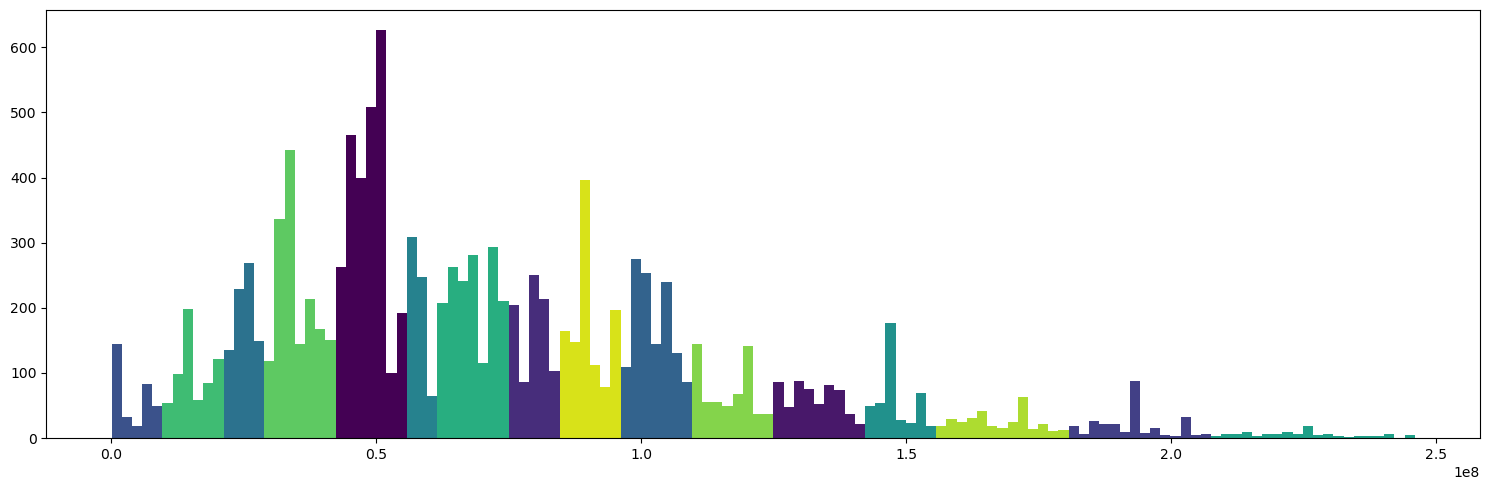

In [7]:
fig, axs = plt.subplots(1, 1, figsize=(15,5), tight_layout=True)

counts, bins, patches = axs.hist(start_positions, bins=128)
bin_norm = colors.Normalize(0, 16)
for count, bin, patch in zip(counts, bins, patches):
    color = plt.cm.viridis(bin_norm(gmm.predict(np.array([[bin]]))))
    patch.set_facecolor(color)

## Export Data

In [8]:
predictions = gmm.predict(start_positions)
with open("roh_start_gmm.csv", "w") as file_handle:
    writer = csv.writer(file_handle)
    writer.writerow([*header, "GMM Group"])
    for index, start_pos in enumerate(rohs[start_pos_key]):
        row = []
        for col in header:
            row.append(rohs[col][index])
        row.append(predictions[index])
        writer.writerow(row)